Libraries imported successfully!
Please upload your marketing campaign CSV file.


Saving marketing_campaign_dataset.csv to marketing_campaign_dataset.csv

Dataset loaded successfully!
Dataset Shape: (200000, 16)

First 5 Rows:
   Campaign_ID              Company Campaign_Type Target_Audience Duration  \
0            1  Innovate Industries         Email       Men 18-24  30 days   
1            2       NexGen Systems         Email     Women 35-44  60 days   
2            3    Alpha Innovations    Influencer       Men 25-34  30 days   
3            4   DataTech Solutions       Display        All Ages  60 days   
4            5       NexGen Systems         Email       Men 25-34  15 days   

  Channel_Used  Conversion_Rate Acquisition_Cost   ROI     Location  Language  \
0   Google Ads             0.04       $16,174.00  6.29      Chicago   Spanish   
1   Google Ads             0.12       $11,566.00  5.61     New York    German   
2      YouTube             0.07       $10,200.00  7.18  Los Angeles    French   
3      YouTube             0.11       $12,724.00  5.55        

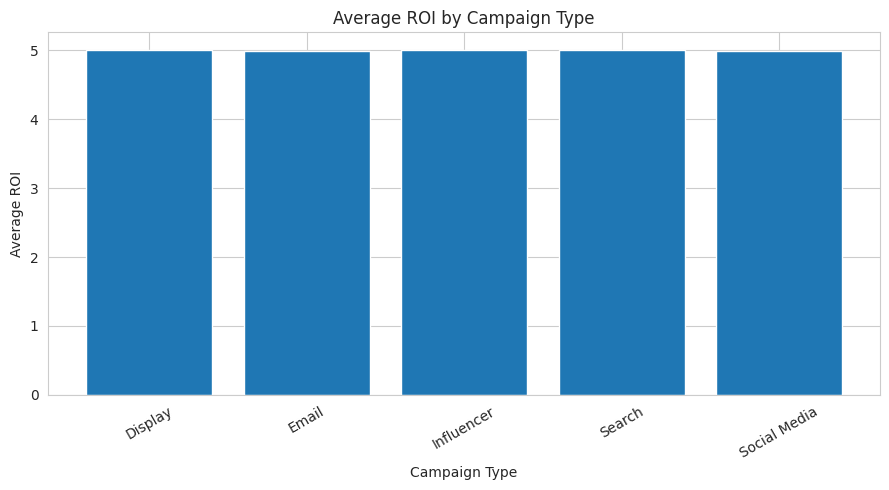

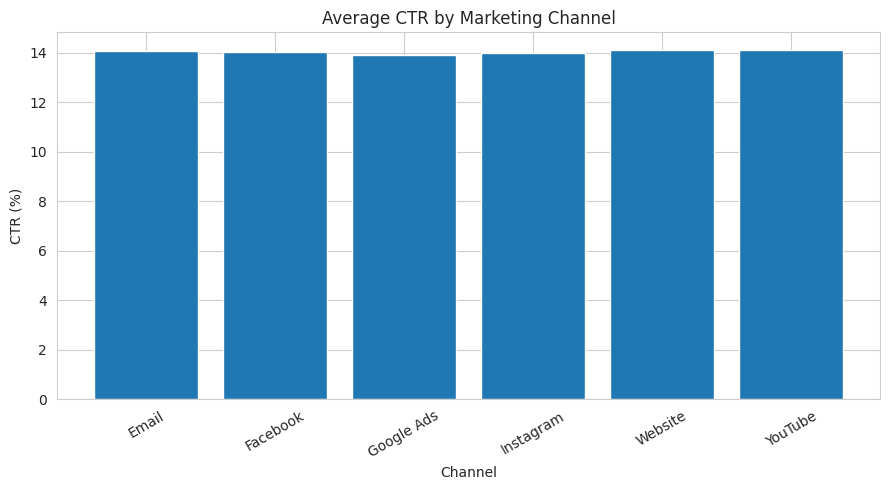

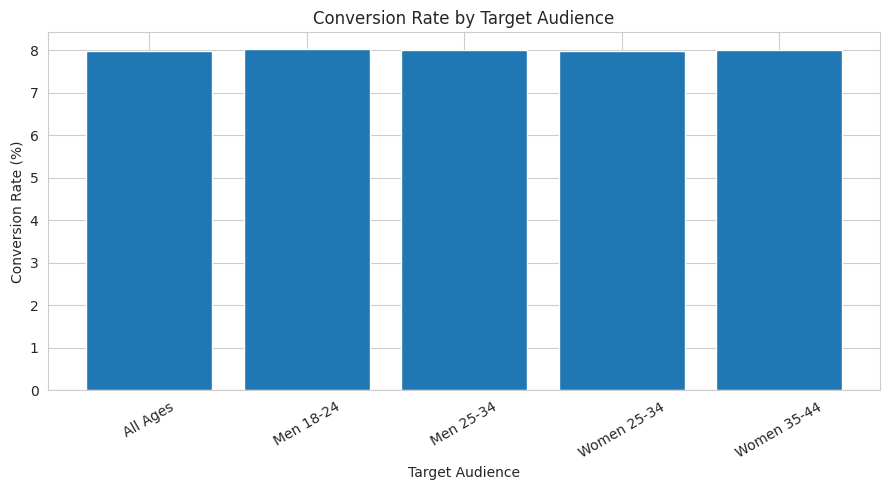

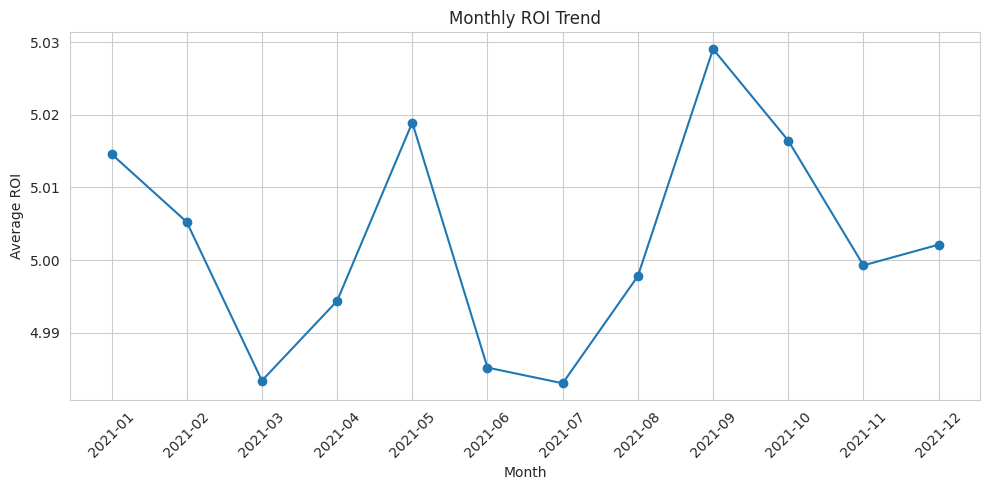


--- STATISTICAL TESTING ---
Kruskal-Wallis Statistic: 7.7247
P-value: 0.172074
Result: No statistically significant ROI differences found.

Note: Statistical significance does not prove that the channel caused the ROI difference.

--- BUSINESS RECOMMENDATIONS ---
Best Campaign Type: Influencer
Average ROI: 5.01
Best Marketing Channel: Facebook
Average ROI: 5.02

Recommendation:
Consider prioritizing campaigns and channels with higher ROI. Also evaluate cost per estimated conversion, engagement, and campaign volume before increasing the marketing budget.

All Reports Exported Successfully!
Task 2 Analysis Completed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# TASK 2: MARKETING CAMPAIGN PERFORMANCE ANALYSIS

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files
import io
import zipfile
import os

print("Libraries imported successfully!")

# 2. UPLOAD DATASET
print("Please upload your marketing campaign CSV file.")

uploaded = files.upload()

file_name = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("\nDataset loaded successfully!")
print("Dataset Shape:", data.shape)
print("\nFirst 5 Rows:")
print(data.head())

# 3. DATA UNDERSTANDING
print("\n--- DATA INFORMATION ---")
data.info()

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:", data.duplicated().sum())

# 4. DATA CLEANING
data.columns = data.columns.str.strip()

# Remove duplicate rows
data = data.drop_duplicates()

# Remove extra spaces from text columns
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()

# Convert date column
if "Date" in data.columns:
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

# Convert acquisition cost into numeric
data["Acquisition_Cost"] = (
    data["Acquisition_Cost"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

data["Acquisition_Cost"] = pd.to_numeric(
    data["Acquisition_Cost"], errors="coerce"
)

# Convert numeric columns
numeric_cols = [
    "Clicks", "Impressions",
    "Conversion_Rate", "ROI", "Engagement_Score"
]

for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Fill missing numeric values using median
for col in data.select_dtypes(include=np.number).columns:
    data[col] = data[col].fillna(data[col].median())

# Remove rows with missing essential values
required_cols = [
    "Campaign_ID", "Campaign_Type", "Channel_Used",
    "Target_Audience", "Clicks", "Impressions",
    "Acquisition_Cost", "Conversion_Rate", "ROI"
]

data = data.dropna(subset=required_cols)

# Remove invalid values
data = data[
    (data["Impressions"] > 0) &
    (data["Clicks"] >= 0) &
    (data["Clicks"] <= data["Impressions"]) &
    (data["Acquisition_Cost"] > 0) &
    (data["Conversion_Rate"] >= 0) &
    (data["ROI"] >= 0)
].copy()

# Normalize conversion rate if stored as percentage
if data["Conversion_Rate"].max() > 1:
    data["Conversion_Rate"] = data["Conversion_Rate"] / 100

print("\nData Cleaning Completed!")
print("Cleaned Dataset Shape:", data.shape)
print("Missing Values After Cleaning:", data.isnull().sum().sum())
print("Duplicates After Cleaning:", data.duplicated().sum())

# 5. CALCULATE MARKETING METRICS

# Click Through Rate
data["CTR"] = (
    data["Clicks"] / data["Impressions"]
) * 100

# Conversion Rate Percentage
data["Conversion_Rate_Percent"] = (
    data["Conversion_Rate"] * 100
)

# Estimated conversions
# Dataset does not contain an actual Conversions column
data["Estimated_Conversions"] = (
    data["Clicks"] * data["Conversion_Rate"]
)

# Cost per estimated conversion
data["Cost_Per_Conversion"] = np.where(
    data["Estimated_Conversions"] > 0,
    data["Acquisition_Cost"] / data["Estimated_Conversions"],
    np.nan
)

# ROI percentage (ROI is treated as a multiplier)
data["ROI_Percent"] = data["ROI"] * 100

# Estimated revenue based on ROI multiplier
data["Estimated_Revenue"] = (
    data["Acquisition_Cost"] * (1 + data["ROI"])
)

print("\nMarketing Metrics Calculated!")
print(data[[
    "Campaign_ID", "CTR",
    "Conversion_Rate_Percent",
    "Estimated_Conversions",
    "Cost_Per_Conversion",
    "ROI_Percent"
]].head())

# 6. OVERALL PERFORMANCE
print("\n--- OVERALL CAMPAIGN PERFORMANCE ---")

print("Total Campaigns:", len(data))
print("Total Impressions:", int(data["Impressions"].sum()))
print("Total Clicks:", int(data["Clicks"].sum()))
print("Total Estimated Conversions:",
      round(data["Estimated_Conversions"].sum(), 2))

print("Average CTR:", round(data["CTR"].mean(), 2), "%")
print("Average Conversion Rate:",
      round(data["Conversion_Rate_Percent"].mean(), 2), "%")

print("Average ROI:", round(data["ROI"].mean(), 2))

print("Total Marketing Spend:",
      round(data["Acquisition_Cost"].sum(), 2))

# 7. CAMPAIGN TYPE ANALYSIS
campaign_analysis = data.groupby("Campaign_Type").agg(
    Total_Impressions=("Impressions", "sum"),
    Total_Clicks=("Clicks", "sum"),
    Average_CTR=("CTR", "mean"),
    Average_Conversion_Rate=("Conversion_Rate_Percent", "mean"),
    Average_ROI=("ROI", "mean"),
    Total_Spend=("Acquisition_Cost", "sum"),
    Average_Engagement=("Engagement_Score", "mean")
).reset_index()

print("\n--- CAMPAIGN TYPE ANALYSIS ---")
print(campaign_analysis.to_string(index=False))

# 8. CHANNEL ANALYSIS
channel_analysis = data.groupby("Channel_Used").agg(
    Total_Impressions=("Impressions", "sum"),
    Total_Clicks=("Clicks", "sum"),
    Average_CTR=("CTR", "mean"),
    Average_Conversion_Rate=("Conversion_Rate_Percent", "mean"),
    Average_ROI=("ROI", "mean"),
    Total_Spend=("Acquisition_Cost", "sum")
).reset_index()

print("\n--- CHANNEL PERFORMANCE ---")
print(channel_analysis.to_string(index=False))

# 9. AUDIENCE ANALYSIS
audience_analysis = data.groupby("Target_Audience").agg(
    Average_CTR=("CTR", "mean"),
    Average_Conversion_Rate=("Conversion_Rate_Percent", "mean"),
    Average_ROI=("ROI", "mean"),
    Total_Spend=("Acquisition_Cost", "sum")
).reset_index()

print("\n--- AUDIENCE PERFORMANCE ---")
print(audience_analysis.to_string(index=False))

# 10. MONTHLY ANALYSIS
if "Date" in data.columns and data["Date"].notna().any():

    data["Month"] = data["Date"].dt.to_period("M").astype(str)

    monthly_analysis = data.groupby("Month").agg(
        Total_Impressions=("Impressions", "sum"),
        Total_Clicks=("Clicks", "sum"),
        Average_CTR=("CTR", "mean"),
        Average_ROI=("ROI", "mean"),
        Total_Spend=("Acquisition_Cost", "sum")
    ).reset_index()

    print("\n--- MONTHLY PERFORMANCE ---")
    print(monthly_analysis.to_string(index=False))

else:
    monthly_analysis = pd.DataFrame()
    print("\nDate data unavailable for monthly analysis.")

# 11. VISUALIZATION

# Campaign Type vs ROI
plt.figure(figsize=(9, 5))
plt.bar(
    campaign_analysis["Campaign_Type"],
    campaign_analysis["Average_ROI"]
)
plt.title("Average ROI by Campaign Type")
plt.xlabel("Campaign Type")
plt.ylabel("Average ROI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Channel vs CTR
plt.figure(figsize=(9, 5))
plt.bar(
    channel_analysis["Channel_Used"],
    channel_analysis["Average_CTR"]
)
plt.title("Average CTR by Marketing Channel")
plt.xlabel("Channel")
plt.ylabel("CTR (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Audience vs Conversion Rate
plt.figure(figsize=(9, 5))
plt.bar(
    audience_analysis["Target_Audience"],
    audience_analysis["Average_Conversion_Rate"]
)
plt.title("Conversion Rate by Target Audience")
plt.xlabel("Target Audience")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Monthly ROI Trend
if not monthly_analysis.empty:
    plt.figure(figsize=(10, 5))
    plt.plot(
        monthly_analysis["Month"],
        monthly_analysis["Average_ROI"],
        marker="o"
    )
    plt.title("Monthly ROI Trend")
    plt.xlabel("Month")
    plt.ylabel("Average ROI")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 12. STATISTICAL SIGNIFICANCE TEST
print("\n--- STATISTICAL TESTING ---")

channel_groups = [
    group["ROI"].values
    for name, group in data.groupby("Channel_Used")
    if len(group) >= 2
]

if len(channel_groups) >= 2:
    statistic, p_value = stats.kruskal(*channel_groups)

    print("Kruskal-Wallis Statistic:", round(statistic, 4))
    print("P-value:", round(p_value, 6))

    if p_value < 0.05:
        print("Result: Significant ROI differences across channels.")
    else:
        print("Result: No statistically significant ROI differences found.")
else:
    p_value = np.nan
    print("Not enough channel groups for statistical testing.")

print("\nNote: Statistical significance does not prove that the channel caused the ROI difference.")

# 13. BUSINESS RECOMMENDATIONS

best_campaign = campaign_analysis.sort_values(
    "Average_ROI", ascending=False
).iloc[0]

best_channel = channel_analysis.sort_values(
    "Average_ROI", ascending=False
).iloc[0]

print("\n--- BUSINESS RECOMMENDATIONS ---")

print("Best Campaign Type:", best_campaign["Campaign_Type"])
print("Average ROI:", round(best_campaign["Average_ROI"], 2))

print("Best Marketing Channel:", best_channel["Channel_Used"])
print("Average ROI:", round(best_channel["Average_ROI"], 2))

print("\nRecommendation:")
print(
    "Consider prioritizing campaigns and channels with higher ROI. "
    "Also evaluate cost per estimated conversion, engagement, and campaign volume "
    "before increasing the marketing budget."
)

# 14. EXPORT REPORTS

data.to_csv("Task_2_Cleaned_Marketing_Data.csv", index=False)

campaign_analysis.to_csv(
    "Campaign_Performance_Report.csv", index=False
)

channel_analysis.to_csv(
    "Channel_Performance_Report.csv", index=False
)

audience_analysis.to_csv(
    "Audience_Performance_Report.csv", index=False
)

if not monthly_analysis.empty:
    monthly_analysis.to_csv(
        "Monthly_Performance_Report.csv", index=False
    )

# Create ZIP file containing all reports
report_files = [
    "Task_2_Cleaned_Marketing_Data.csv",
    "Campaign_Performance_Report.csv",
    "Channel_Performance_Report.csv",
    "Audience_Performance_Report.csv"
]

if not monthly_analysis.empty:
    report_files.append("Monthly_Performance_Report.csv")

with zipfile.ZipFile(
    "Task_2_Analysis_Reports.zip", "w"
) as zip_file:
    for report in report_files:
        zip_file.write(report)

print("\nAll Reports Exported Successfully!")
print("Task 2 Analysis Completed!")

# Download all CSV reports together
files.download("Task_2_Analysis_Reports.zip")
